<a href="https://colab.research.google.com/github/tkach3nkoo/MN/blob/main/%D0%9B%D0%A04_%D0%A2%D0%BA%D0%B0%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B3%D1%80%D1%83%D0%BF%D0%B0_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/Mugangasia/car-prediction-model/master/CarPrice_Assignment.csv"
try:
    df = pd.read_csv("CarPrice_Assignment.csv")
except FileNotFoundError:
    df = pd.read_csv(DATA_URL)

print("Розмір даних:", df.shape)
print("Стовпці:", df.columns.tolist())
print("Типи даних:")
print(df.dtypes.to_string())
print("Цільова змінна: price")
display(df.head())
display(df.describe(include="all").T)
print("Висновок: ціль — неперервна ціна автомобіля; задача є регресією.")

Розмір даних: (205, 26)
Стовпці: ['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionratio    float64
horsepower            

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_ID,205.0,NaN,NaN,NaN,103.0,59.322565,1.0,52.0,103.0,154.0,205.0
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
CarName,205,147,peugeot 504,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fueltype,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doornumber,205,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carbody,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drivewheel,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enginelocation,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheelbase,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9


Висновок: ціль — неперервна ціна автомобіля; задача є регресією.


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Пропущені значення за стовпцями:")
display(df.isna().sum().to_frame("Пропущено"))
print("Повні дублікати (усі стовпці):", df.duplicated().sum())
print("Дублікати без car_ID:", df.drop(columns="car_ID").duplicated().sum())
characteristic_columns = df.columns.drop(["car_ID", "price"])
print("Однакові характеристики без car_ID і price:", df.duplicated(subset=characteristic_columns).sum())
print("Кількість унікальних значень:")
display(df.nunique().to_frame("Унікальних значень"))
print("Висновок: car_ID не враховується при змістовній перевірці дублікатів; "+
      ("пропусків немає." if df.isna().sum().sum() == 0 else "наявні пропуски, їх потрібно обробляти."))

Пропущені значення за стовпцями:


,Пропущено
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Повні дублікати (усі стовпці): 0
Дублікати без car_ID: 0
Однакові характеристики без car_ID і price: 0
Кількість унікальних значень:


,Унікальних значень
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


Висновок: car_ID не враховується при змістовній перевірці дублікатів; пропусків немає.


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids = df["car_ID"].copy()
features = df.drop(columns=["car_ID", "price"])
print("Збережено car_ID:", len(car_ids), "значень.")
print("car_ID відсутній серед предикторів:", "car_ID" not in features.columns)
print("Висновок: ідентифікатор збережено окремо, щоб не використовувати його в регресії.")

Збережено car_ID: 205 значень.
car_ID відсутній серед предикторів: True
Висновок: ідентифікатор збережено окремо, щоб не використовувати його в регресії.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


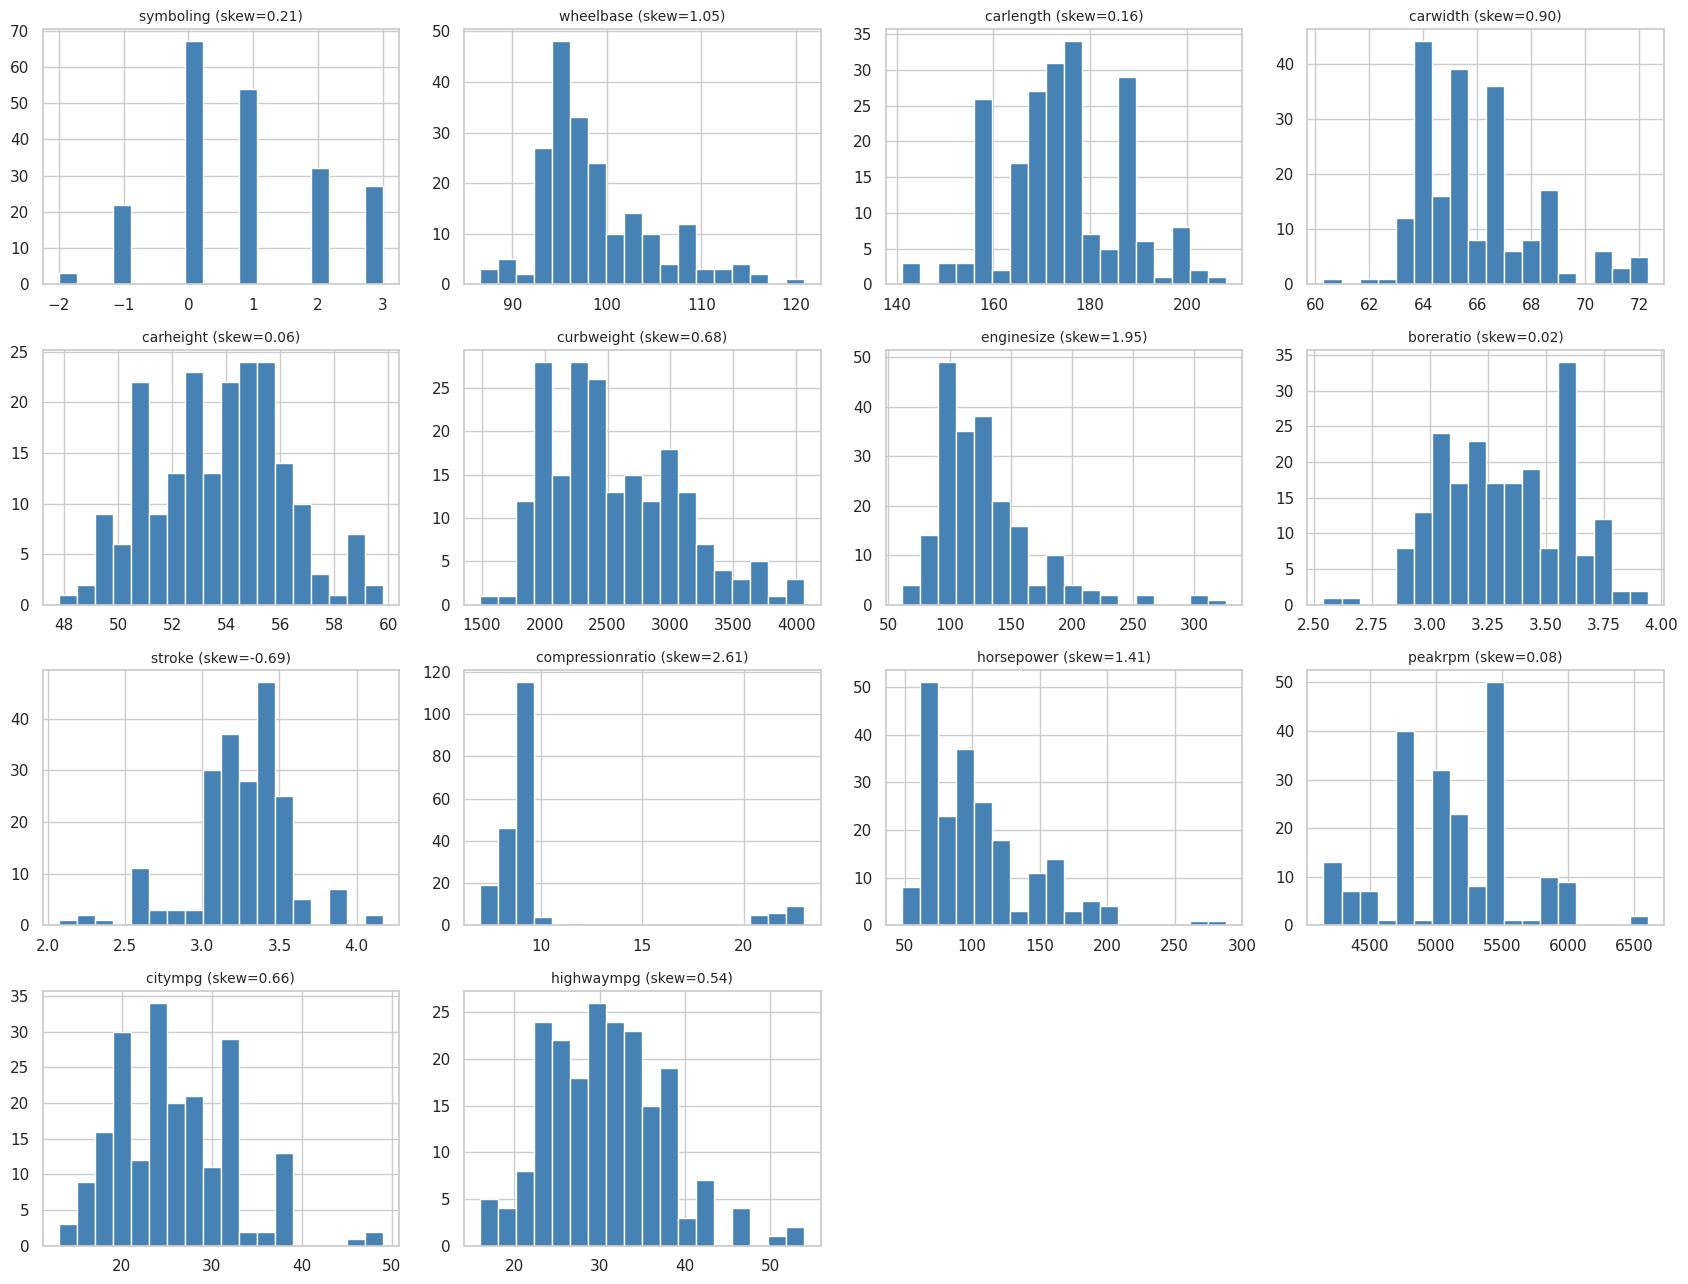

,Асиметрія
compressionratio,2.610862
enginesize,1.947655
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072


Найвираженіша асиметрія: compressionratio, enginesize, horsepower
Висновок: великі за модулем коефіцієнти асиметрії свідчать про довгі хвости розподілу.


In [ ]:
numeric_features = df.select_dtypes(include=np.number).columns.drop(["car_ID", "price"])
skewness = df[numeric_features].skew().sort_values(key=lambda x: x.abs(), ascending=False)
fig, axes = plt.subplots(nrows=int(np.ceil(len(numeric_features) / 4)), ncols=4, figsize=(17, 13))
for ax, col in zip(axes.flat, numeric_features):
    ax.hist(df[col].dropna(), bins=18, color="steelblue", edgecolor="white")
    ax.set_title(f"{col} (skew={skewness[col]:.2f})", fontsize=10)
for ax in axes.flat[len(numeric_features):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
display(skewness.to_frame("Асиметрія"))
print("Найвираженіша асиметрія:", ", ".join(skewness.abs().nlargest(3).index))
print("Висновок: великі за модулем коефіцієнти асиметрії свідчать про довгі хвости розподілу.")

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
X = features.copy()
y = df["price"].copy()
X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)
print("ID train/test:", ids_train.shape, ids_test.shape)
print("Перетин ID train/test:", len(set(ids_train) & set(ids_test)))
print("Висновок: 80% даних використовується для навчання, 20% — для фінального тестування.")

X_train: (164, 24) X_test: (41, 24)
y_train: (164,) y_test: (41,)
ID train/test: (164,) (41,)
Перетин ID train/test: 0
Висновок: 80% даних використовується для навчання, 20% — для фінального тестування.


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
continuous_all = X_train.select_dtypes(include=np.number).columns.drop("symboling").tolist()
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()
iqr_limits = {}
outlier_stats = []
for col in continuous_all:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_limits[col] = (lower, upper)
    mask = (X_train[col] < lower) | (X_train[col] > upper)
    outlier_stats.append({"Ознака": col, "Потенційних викидів train": int(mask.sum()),
                          "Нижня межа": lower, "Верхня межа": upper})
    X_train_capped[col] = X_train[col].clip(lower=lower, upper=upper)
    X_test_capped[col] = X_test[col].clip(lower=lower, upper=upper)

display(pd.DataFrame(outlier_stats).set_index("Ознака"))
print("Висновок: викиди обмежено методом IQR без видалення рядків. "+
      "Межі обчислено виключно на train і застосовано до test; price не використовувалась.")

,Потенційних викидів train,Нижня межа,Верхня межа
Ознака,,,
wheelbase,6,83.1000,113.5000
carlength,0,141.8875,207.9875
carwidth,10,60.4250,70.4250
carheight,0,46.4625,60.9625
curbweight,0,998.6250,4103.6250
enginesize,7,33.5000,205.5000
boreratio,1,2.5650,4.1250
stroke,16,2.6600,3.8600
compressionratio,20,7.4000,10.6000


Висновок: викиди обмежено методом IQR без видалення рядків. Межі обчислено виключно на train і застосовано до test; price не використовувалась.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


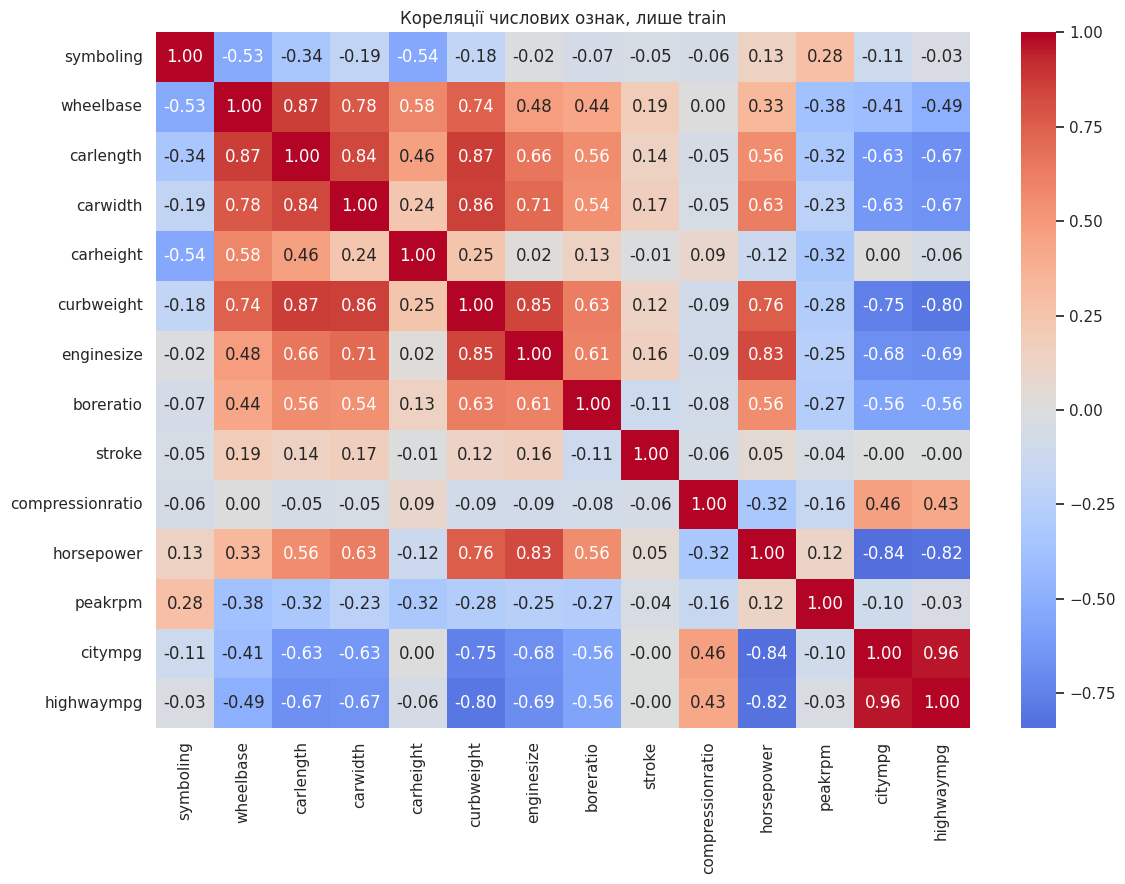

Пари з |r| > 0.85:


,Перша,Друга,r,"|r(price, перша)|","|r(price, друга)|",Залишена ознака
0,citympg,highwaympg,0.963620,0.711245,0.716460,highwaympg
1,wheelbase,carlength,0.867043,0.504036,0.652071,wheelbase
2,carlength,curbweight,0.865988,0.652071,0.824212,curbweight
3,carwidth,curbweight,0.858047,0.731623,0.824212,curbweight


Видалено ознаки: ['carlength', 'carwidth', 'citympg']
Розміри після відбору: (164, 21) (41, 21)
Висновок: серед сильно пов’язаних числових ознак залишено ті, що сильніше корелюють із price на train; test не впливав на вибір.


In [ ]:
numeric_all = X_train_capped.select_dtypes(include=np.number).columns.tolist()
correlation_matrix = X_train_capped[numeric_all].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Кореляції числових ознак, лише train")
plt.tight_layout()
plt.show()

corr_to_price = X_train_capped[numeric_all].corrwith(y_train)
strong_pairs = []
for i, first in enumerate(numeric_all):
    for second in numeric_all[i+1:]:
        r = correlation_matrix.loc[first, second]
        if abs(r) > 0.85:
            strong_pairs.append((first, second, r))
strong_pairs.sort(key=lambda row: abs(row[2]), reverse=True)

# Пріоритет надаємо ознакам із сильнішим зв'язком із ціною.
# Кандидат залишається, тільки якщо не дублює жодної вже відібраної ознаки.
ordered_numeric = sorted(numeric_all, key=lambda col: abs(corr_to_price[col]), reverse=True)
kept_numeric = []
removed_features = []
for col in ordered_numeric:
    if any(abs(correlation_matrix.loc[col, kept]) > 0.85 for kept in kept_numeric):
        removed_features.append(col)
    else:
        kept_numeric.append(col)
comparisons = []
for first, second, r in strong_pairs:
    comparisons.append({"Перша": first, "Друга": second, "r": r,
                        "|r(price, перша)|": abs(corr_to_price[first]),
                        "|r(price, друга)|": abs(corr_to_price[second]),
                        "Залишена ознака": ", ".join(c for c in (first, second) if c in kept_numeric)})
print("Пари з |r| > 0.85:")
display(pd.DataFrame(comparisons))
removed_features = sorted(removed_features)
print("Видалено ознаки:", removed_features)
X_train_selected = X_train_capped.drop(columns=removed_features)
X_test_selected = X_test_capped.drop(columns=removed_features)
print("Розміри після відбору:", X_train_selected.shape, X_test_selected.shape)
print("Висновок: серед сильно пов’язаних числових ознак залишено ті, "+
      "що сильніше корелюють із price на train; test не впливав на вибір.")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
continuous_features = [col for col in continuous_all if col in X_train_selected.columns]
discrete_features = ["symboling"] if "symboling" in X_train_selected.columns else []
categorical_features = X_train_selected.select_dtypes(exclude=np.number).columns.tolist()

continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler())
])
preprocessor = ColumnTransformer(transformers=[
    ("continuous", continuous_pipeline, continuous_features),
    ("symboling", StandardScaler(), discrete_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
], remainder="drop")

print("Неперервні числові:", continuous_features)
print("Дискретна числова:", discrete_features)
print("Категоріальні:", categorical_features)
print("Висновок: єдиний ColumnTransformer виконує Yeo–Johnson → StandardScaler, "+
      "окреме масштабування symboling та One-Hot Encoding з обробкою невідомих категорій.")

Неперервні числові: ['wheelbase', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова: ['symboling']
Категоріальні: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']
Висновок: єдиний ColumnTransformer виконує Yeo–Johnson → StandardScaler, окреме масштабування symboling та One-Hot Encoding з обробкою невідомих категорій.


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
# Перевірка лише на train; ті самі кроки використовуються у моделях.
preprocessor_check = clone(preprocessor)
preprocessor_check.fit(X_train_selected)
cont_transformed = preprocessor_check.named_transformers_["continuous"].transform(
    X_train_selected[continuous_features]
)
before_skew = X_train_selected[continuous_features].skew()
after_skew = pd.DataFrame(cont_transformed, columns=continuous_features).skew()
skew_comparison = pd.DataFrame({
    "Асиметрія до": before_skew,
    "Асиметрія після": after_skew,
    "|До|": before_skew.abs(),
    "|Після|": after_skew.abs()
})
display(skew_comparison.sort_values("|До|", ascending=False))
improved_count = int((skew_comparison["|Після|"] < skew_comparison["|До|"]).sum())
print(f"Висновок: Yeo–Johnson зменшив абсолютну асиметрію для {improved_count} із {len(continuous_features)} ознак.")

,Асиметрія до,Асиметрія після,|До|,|Після|
enginesize,0.962394,0.044834,0.962394,0.044834
wheelbase,0.935764,0.022553,0.935764,0.022553
horsepower,0.850735,0.066280,0.850735,0.066280
curbweight,0.712433,0.049894,0.712433,0.049894
stroke,-0.397600,0.015846,0.397600,0.015846
highwaympg,0.243761,-0.012188,0.243761,0.012188
boreratio,0.062963,-0.005941,0.062963,0.005941
compressionratio,0.055710,0.004872,0.055710,0.004872
peakrpm,0.039773,-0.003589,0.039773,0.003589
carheight,0.028154,-0.005170,0.028154,0.005170


Висновок: Yeo–Johnson зменшив абсолютну асиметрію для 10 із 10 ознак.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Lasso Regression": Lasso(alpha=100.0, max_iter=20000),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=3, random_state=42),
    "Support Vector Regressor (SVR)": SVR(C=10000, epsilon=250)
}
models = {
    name: Pipeline([("preprocessing", clone(preprocessor)), ("regressor", estimator)])
    for name, estimator in regressors.items()
}
for name, model in models.items():
    model.fit(X_train_selected, y_train)
    print("Навчено:", name)
print("Висновок: усі шість моделей навчені з однаковою схемою передобробки тільки на train.")

Навчено: Linear Regression


Навчено: Ridge Regression


Навчено: Lasso Regression


Навчено: Random Forest Regressor
Навчено: Gradient Boosting Regressor


Навчено: Support Vector Regressor (SVR)
Висновок: усі шість моделей навчені з однаковою схемою передобробки тільки на train.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
predictions = {}
metrics_rows = []
train_r2 = {}
for name, model in models.items():
    y_pred = model.predict(X_test_selected)
    predictions[name] = y_pred
    train_r2[name] = r2_score(y_train, model.predict(X_train_selected))
    metrics_rows.append({
        "Модель": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100,
    })
results = pd.DataFrame(metrics_rows).sort_values("R²", ascending=False).reset_index(drop=True)
display(results.round(3))
print("Найбільший R²:", results.loc[0, "Модель"])
print("Найменший MAE:", results.loc[results["MAE"].idxmin(), "Модель"])
print("Найменший MSE:", results.loc[results["MSE"].idxmin(), "Модель"])
print("Найменший MAPE:", results.loc[results["MAPE (%)"].idxmin(), "Модель"])
print("Висновок: R² слід максимізувати, а MAE, MSE та MAPE мінімізувати.")
print("Порівняння R² на train та test (оцінка можливого перенавчання):")
overfit_check = pd.DataFrame({
    "Модель": list(train_r2),
    "R² train": list(train_r2.values()),
    "R² test": [r2_score(y_test, predictions[name]) for name in train_r2]
})
overfit_check["Різниця R²"] = overfit_check["R² train"] - overfit_check["R² test"]
display(overfit_check.round(3).sort_values("Різниця R²", ascending=False))

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.953,1361.078,3.706472e+06,9.834
1,Gradient Boosting Regressor,0.933,1660.535,5.263284e+06,12.137
2,Support Vector Regressor (SVR),0.858,2164.579,1.120832e+07,17.216
3,Lasso Regression,0.775,2894.481,1.775217e+07,23.478
4,Ridge Regression,0.731,3195.930,2.121681e+07,27.986
5,Linear Regression,0.530,4184.331,3.711949e+07,30.634


Найбільший R²: Random Forest Regressor
Найменший MAE: Random Forest Regressor
Найменший MSE: Random Forest Regressor
Найменший MAPE: Random Forest Regressor
Висновок: R² слід максимізувати, а MAE, MSE та MAPE мінімізувати.
Порівняння R² на train та test (оцінка можливого перенавчання):


,Модель,R² train,R² test,Різниця R²
0,Linear Regression,0.993,0.530,0.463
1,Ridge Regression,0.864,0.731,0.133
5,Support Vector Regressor (SVR),0.966,0.858,0.108
2,Lasso Regression,0.853,0.775,0.078
4,Gradient Boosting Regressor,0.994,0.933,0.060
3,Random Forest Regressor,0.976,0.953,0.023


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування `price` — це **задача регресії**, оскільки потрібно передбачити неперервне числове значення ціни. Logistic Regression призначена для **класифікації** й оцінює ймовірності класів, тому не прогнозує безпосередньо довільну неперервну ціну. Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor та SVR повертають числовий прогноз і відповідають задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


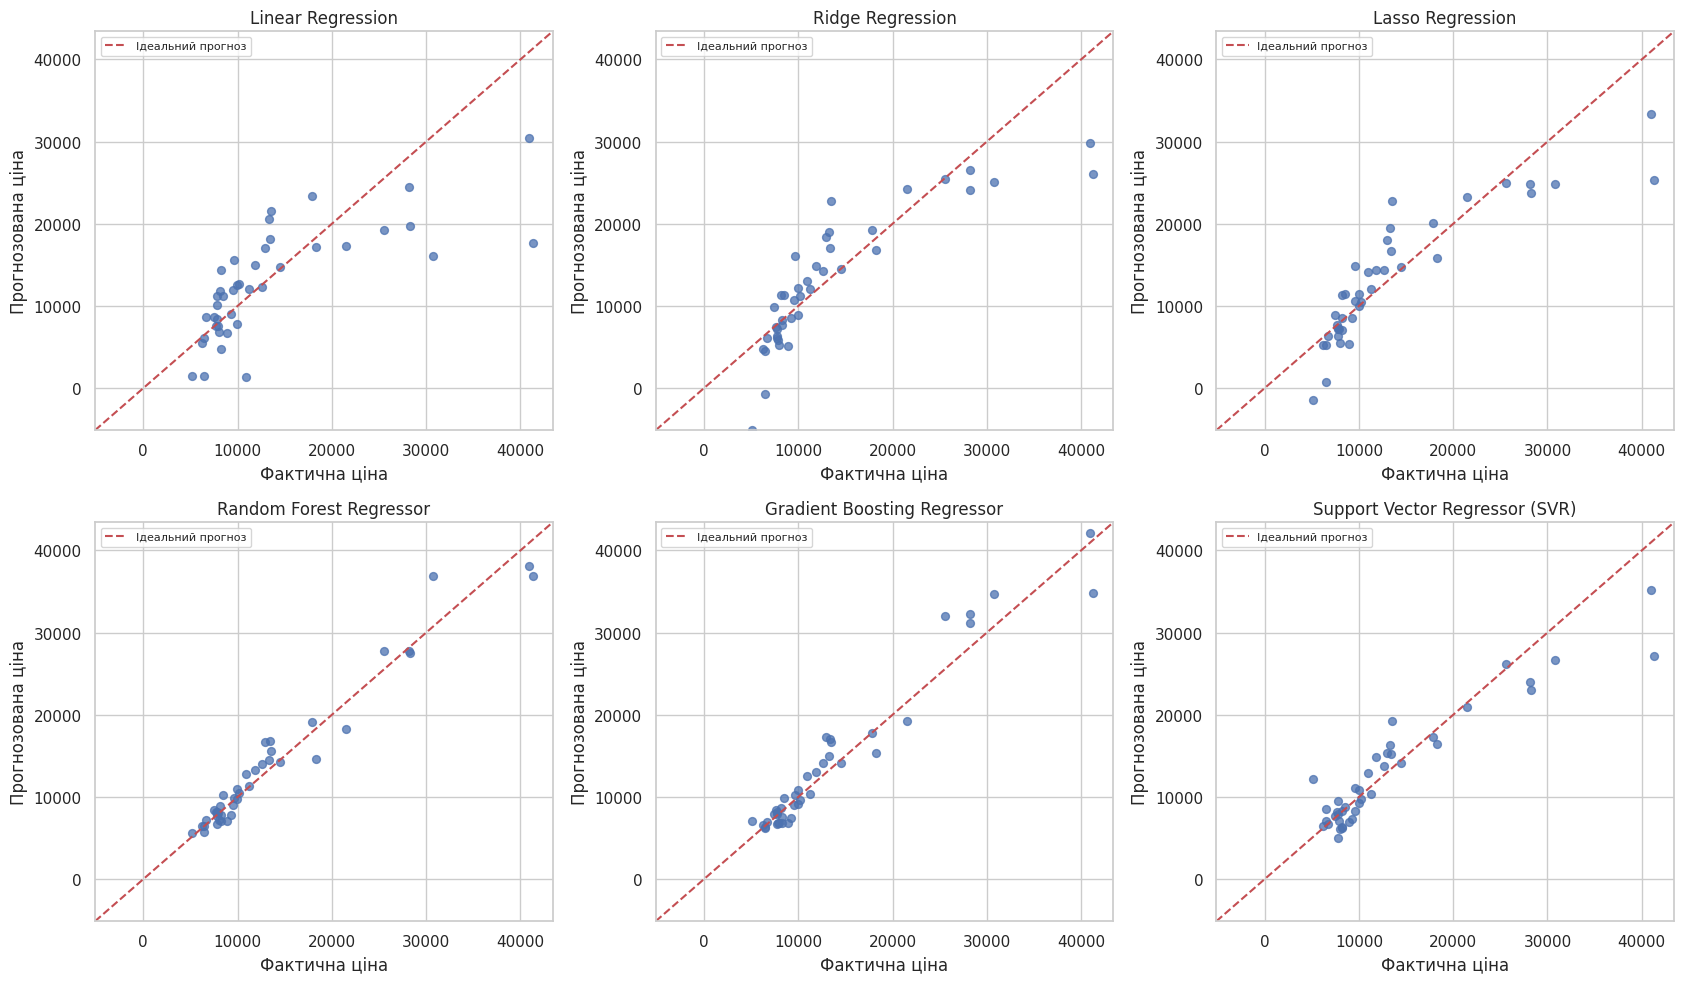

Linear Regression: середнє відхилення = 4184.33, найбільше = 23697.83
Ridge Regression: середнє відхилення = 3195.93, найбільше = 15243.39
Lasso Regression: середнє відхилення = 2894.48, найбільше = 15969.43
Random Forest Regressor: середнє відхилення = 1361.08, найбільше = 6117.15
Gradient Boosting Regressor: середнє відхилення = 1660.54, найбільше = 6471.75
Support Vector Regressor (SVR): середнє відхилення = 2164.58, найбільше = 14203.27
Висновок: точки ближче до червоної діагоналі означають точніші прогнози; віддалені точки вказують на великі помилки.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
all_values = np.concatenate([y_test.to_numpy()] + list(predictions.values()))
low = min(float(all_values.min()), 0)
high = float(all_values.max()) * 1.03
for ax, (name, predicted) in zip(axes.flat, predictions.items()):
    ax.scatter(y_test, predicted, alpha=0.75, s=32)
    ax.plot([low, high], [low, high], "r--", label="Ідеальний прогноз")
    ax.set(xlabel="Фактична ціна", ylabel="Прогнозована ціна", title=name,
           xlim=(low, high), ylim=(low, high))
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
for name, predicted in predictions.items():
    errors = abs(y_test.to_numpy() - predicted)
    print(f"{name}: середнє відхилення = {errors.mean():.2f}, "
          f"найбільше = {errors.max():.2f}")
print("Висновок: точки ближче до червоної діагоналі означають точніші прогнози; "+
      "віддалені точки вказують на великі помилки.")

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
random_sample = X_test_selected.sample(n=10, random_state=42)
sample_predicted = models["Random Forest Regressor"].predict(random_sample)
sample_actual = y_test.loc[random_sample.index]
rf_sample = pd.DataFrame({
    "car_ID": ids_test.loc[random_sample.index].to_numpy(),
    "Фактична ціна": sample_actual.to_numpy(),
    "Прогнозована ціна": sample_predicted,
})
rf_sample["Абсолютна помилка"] = abs(rf_sample["Фактична ціна"] - rf_sample["Прогнозована ціна"])
rf_sample["Абсолютна відсоткова помилка (%)"] = (
    rf_sample["Абсолютна помилка"] / rf_sample["Фактична ціна"] * 100
)
display(rf_sample.round(2).reset_index(drop=True))
print(f"Середня абсолютна помилка цих 10 автомобілів: {rf_sample['Абсолютна помилка'].mean():.2f}")
print(f"Середня абсолютна відсоткова помилка: {rf_sample['Абсолютна відсоткова помилка (%)'].mean():.2f}%")
worst = rf_sample.loc[rf_sample["Абсолютна помилка"].idxmax()]
print(f"Найбільше відхилення для car_ID={int(worst['car_ID'])}: {worst['Абсолютна помилка']:.2f}.")
print("Висновок: похибки різняться між автомобілями; важливо аналізувати не лише усереднені метрики.")

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7190.14,498.14,7.44
1,176,9988.0,10931.66,943.66,9.45
2,148,10198.0,10520.60,322.60,3.16
3,17,41315.0,36841.04,4473.96,10.83
4,69,28248.0,27488.70,759.30,2.69
5,147,7463.0,8388.48,925.48,12.40
6,144,9960.0,9732.28,227.72,2.29
7,85,14489.0,14223.80,265.20,1.83
8,195,12940.0,16718.17,3778.17,29.20
9,160,7788.0,7685.40,102.60,1.32


Середня абсолютна помилка цих 10 автомобілів: 1229.68
Середня абсолютна відсоткова помилка: 8.06%
Найбільше відхилення для car_ID=17: 4473.96.
Висновок: похибки різняться між автомобілями; важливо аналізувати не лише усереднені метрики.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


За підсумками тестування на **41 автомобілі** (навчання — 164 автомобілі) найкращою виявилася модель **Random Forest Regressor**: **R² = 0.953, MAE = 1361.08, MSE = 3 706 472, MAPE = 9.83%**. Вона має найкращі значення всіх чотирьох тестових метрик. На другому місці — Gradient Boosting Regressor (**R² = 0.933, MAE = 1660.54, MSE = 5 263 284, MAPE = 12.14%**).

Інші моделі показали слабші результати: **SVR** (R² = 0.858; MAE = 2164.58; MSE = 11 208 320; MAPE = 17.22%), **Lasso** (R² = 0.775; MAE = 2894.48; MSE = 17 752 170; MAPE = 23.48%), **Ridge** (R² = 0.731; MAE = 3195.93; MSE = 21 216 810; MAPE = 27.99%) і **Linear Regression** (R² = 0.530; MAE = 4184.33; MSE = 37 119 490; MAPE = 30.63%). Для Random Forest середня абсолютна помилка становить приблизно **1361** одиницю ціни, але максимальна індивідуальна помилка на test сягає **6117**: навіть найкраща модель не однаково точна для всіх автомобілів.

Помітне **перенавчання Linear Regression** (R² на train = 0.993, на test = 0.530), що узгоджується з малою вибіркою та великою кількістю ознак після One-Hot Encoding. У Random Forest різниця значно менша (R² на train = 0.976, на test = 0.953); для Gradient Boosting — 0.994 проти 0.933. Ridge і Lasso частково обмежують складність лінійної моделі, але в цій роботі поступаються ансамблям.

Попередня обробка виконана **без витоку даних із test**: межі IQR, відбір корельованих ознак, Yeo–Johnson, масштабування й кодування визначалися лише на train. Межі IQR дозволили зберегти всі спостереження, видалено три сильно корельовані ознаки, а Yeo–Johnson зменшив абсолютну асиметрію всіх десяти відібраних неперервних числових ознак. Ці перетворення роблять підготовку даних послідовною, але їхній окремий внесок у точність без додаткового порівняння *з/без передобробки* кількісно оцінити не можна.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
